# Задание на лабораторную работу №2. Pandas и основы python
## Общее задание
1. Сгенерировать с использованием библиотеки pandas csv файл, содержащий 3 столбца: $x_1$, $x_2$, $y$ (> 400 строк, генерация с использованием функции linspace). Вид функции определяется вариантом (диапазон выбирается студентом).
2. Открыть файл с использованием библиотеки pandas и построить графики: $y(x_1)$ ($x_2$ - константа), $y(x_2)$  ($x_1$ - константа). Графики необходимо построить с использованием matplotlib (для функции y отобразить точки на графике). 
3. Вывести для каждого столбца $(x_1, x_2, y)$: среднее, минимальное и максимальное значения.
4. Сохранить в новый csv файл те строки, для которых выполняется условие: $x_1$ меньше среднее $x_1$ или $x_2$ меньше среднее $x_2$
5. С использованием mplot3D построить 3D график функции $y(x_1, x_2)$ в отдельном окне.

## Варианты
1. $y = sin(x_1 + x_2)$
2. $y = cos(x_1 + x_2)$
3. $y = tan(x_1 + x_2) * sin(x_1)$
4. $y = 2 * x_1^2 + 3x_2^2$
5. $y = 5 * log(x_1) * log(2 * x_2)$
6. $y = 5 * log(x_1) * x_2^2$
7. $y = cos(x_1) * x_2^3$
8. $y = \frac{3}{(2 + e^{-2x})}$
9. $y = cos(x_1 + x_2) * x_2 ^ 2$
10. $y = \frac{x_2}{(1 + e^{-x_1})}$
11. $y = \frac{3 * x_1}{(1 - e^{-x_2})}$
12. $y = 0.01 * tan(x_1) * x_2^2$
13. $y = x_1^6 + x_2^2 + x_1^3 + 4x_2 + 5$
14. $y = cos(x_1) * x_2^3$
15. $y = tan(x_1) * ctg(x_2)$
16. $y = \frac{sin(x_1)}{(1 + e^{-2x_2})}$
17. $y = \frac{cos(x_1)}{(1 + e^{-2x_2})}$
18. $y = \frac{tan(x_1)}{(3 + e^{-2x_2})}$
19. $y = \frac{ctg(x_1)}{(2 + e^{-2x_2})}$
20. $y = \frac{x_1^2}{(1 + e^{-2x_2})}$


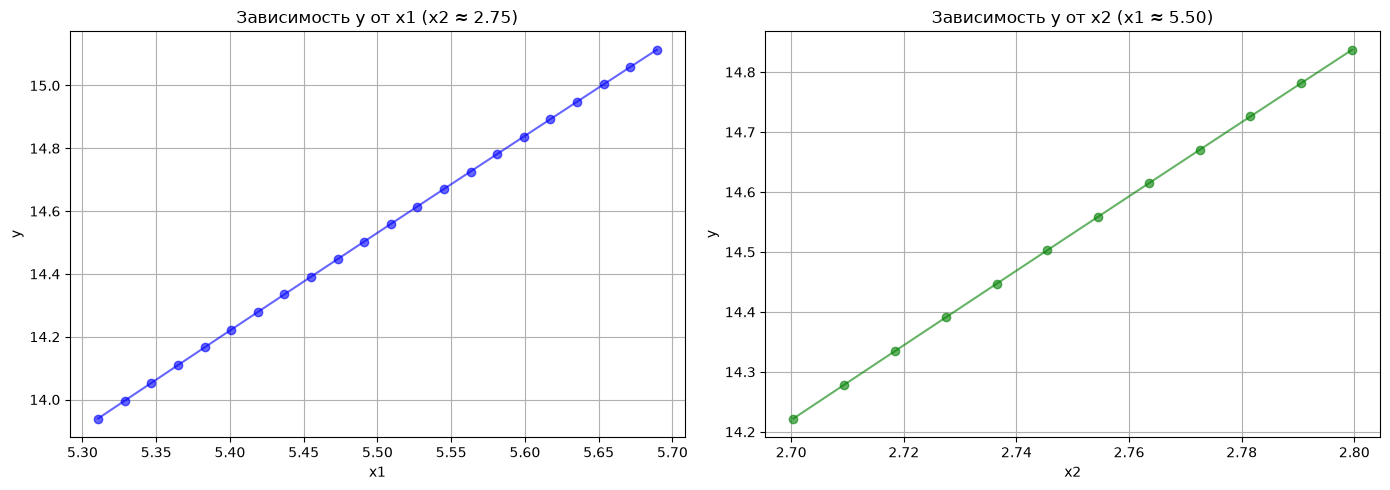

Статистика по столбцам:
        x1    x2      y
mean   5.5  2.75  13.87
min    1.0  0.50   0.00
max   10.0  5.00  26.51


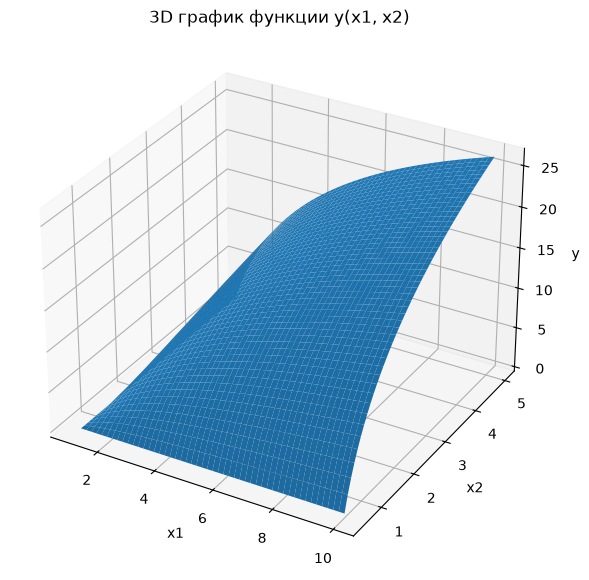

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1
x1 = np.linspace(1, 10, 500)
x2 = np.linspace(0.5, 5, 500)
def func(x1, x2):
    return 5 * np.log(x1) * np.log(2 * x2)

y = func(x1, x2)
df = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y})
df.to_csv('data-lab2.csv', index=False)

# 2
df = pd.read_csv('data-lab2.csv')
const_x1 = 5.5
const_x2 = 2.75

# Для графика y(x1) берем строки, где x2 близок к константе
df_for_x1 = df[(df['x2'] - const_x2).abs() < 0.1]
# Для графика y(x2) берем строки, где x1 близок к константе
df_for_x2 = df[(df['x1'] - const_x1).abs() < 0.1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# График 1: y от x1 (x2 - константа)
axes[0].plot(df_for_x1['x1'], df_for_x1['y'], linestyle='-', marker='o', markersize=6, alpha=0.6, color='blue')
axes[0].set_title(f'Зависимость y от x1 (x2 ≈ {const_x2:.2f})')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('y')
axes[0].grid(True)

# График 2: y от x2 (x1 - константа)
axes[1].plot(df_for_x2['x2'], df_for_x2['y'], linestyle='-', marker='o', markersize=6, alpha=0.6, color='green')
axes[1].set_title(f'Зависимость y от x2 (x1 ≈ {const_x1:.2f})')
axes[1].set_xlabel('x2')
axes[1].set_ylabel('y')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 3
stats = df.agg(['mean', 'min', 'max'])
print("Статистика по столбцам:")
print(stats.round(2))
# 4
mean_x1 = df['x1'].mean()
mean_x2 = df['x2'].mean()
filtered_df = df[(df['x1'] < mean_x1) | (df['x2'] < mean_x2)]
filtered_df.to_csv('filtered-data-lab2.csv', index=False)

# 5
x1_grid = np.linspace(1, 10, 50)
x2_grid = np.linspace(0.5, 5, 50)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
Y = func(X1, X2)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X1, X2, Y)
ax.set_title('3D график функции y(x1, x2)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')

plt.show()
